# Chronos vs ETS — gạo xuất khẩu

So tầng foundation model (zero-shot quantile) với baseline ETS trên chuỗi gạo.

**Alert Chronos:** WARN nếu thực tế ngoài khoảng dự báo 1-bước `[q_lo, q_hi]` xây từ context `[:t)`.

**Cài đặt (một lần):**
```powershell
pip install -r requirements-chronos.txt
```

Nếu tải model thất bại, notebook ghi báo cáo BLOCKED — ETS vẫn là baseline.


## 1. Cấu hình & thư viện


In [1]:
from __future__ import annotations

import json
import traceback
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path("..").resolve()
if not (ROOT / "data" / "csv" / "xuat_khau").exists():
    ROOT = Path(".").resolve()

DATA = ROOT / "data" / "csv" / "xuat_khau" / "gạo.csv"
OUT = ROOT / "reports" / "eval"
BASELINE_JSON = OUT / "baseline_ets.json"
MIN_CONTEXT = 60
INJECT = [1.2, 1.5, 2.0, 3.0, 0.7, 0.5, 0.3]

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 4)
print("DATA exists:", DATA.exists())
print("BASELINE exists:", BASELINE_JSON.exists())


DATA exists: True
BASELINE exists: True


## 2. Protocol helpers + load dữ liệu


In [2]:
KEY_FACTORS = ["x2.0", "x0.5"]


def mean_key_recall(recall: dict) -> float:
    vals = []
    for col_rec in recall.values():
        for f in KEY_FACTORS:
            if f in col_rec:
                vals.append(col_rec[f])
    return float(np.mean(vals)) if vals else float("nan")


def beats_baseline(candidate: dict, baseline: dict) -> dict:
    c_rec = mean_key_recall(candidate.get("synthetic_recall", {}))
    b_rec = mean_key_recall(baseline.get("synthetic_recall", {}))
    c_rate = candidate.get("alerts_per_year", {}).get("WARN_or_CRITICAL", np.nan)
    b_rate = baseline.get("alerts_per_year", {}).get("WARN_or_CRITICAL", np.nan)
    better_recall = (c_rec - b_rec) >= 0.05 if np.isfinite(c_rec) and np.isfinite(b_rec) else False
    if np.isfinite(c_rate) and np.isfinite(b_rate) and b_rate > 0:
        rate_ok = c_rate <= 2.0 * b_rate
    elif np.isfinite(c_rate) and np.isfinite(b_rate):
        rate_ok = c_rate <= max(2.0, b_rate)
    else:
        rate_ok = False
    return {
        "candidate_key_recall": round(c_rec, 3) if np.isfinite(c_rec) else None,
        "baseline_key_recall": round(b_rec, 3) if np.isfinite(b_rec) else None,
        "candidate_alerts_per_year": c_rate,
        "baseline_alerts_per_year": b_rate,
        "better_recall": bool(better_recall),
        "rate_ok": bool(rate_ok),
        "wins": bool(better_recall and rate_ok),
        "rule": "key_recall(x2,x0.5) +0.05 AND alerts/year <= 2x baseline",
    }


def load_rice() -> pd.DataFrame:
    df = pd.read_csv(DATA, parse_dates=["thang_nam"]).set_index("thang_nam").sort_index()
    df = df.asfreq("MS")
    df["don_gia"] = df["tri_gia"] / df["so_luong"]
    return df


## 3. Load Chronos pipeline

Ưu tiên Chronos-2; fallback Bolt / T5-small. Bolt chỉ hỗ trợ quantile 0.1–0.9.

Nếu import/tải model thất bại: ghi JSON blocker và dừng — xem cell verdict.


In [3]:
def try_load_pipeline():
    from chronos import BaseChronosPipeline

    model_ids = [
        "amazon/chronos-2-small",
        "amazon/chronos-bolt-small",
        "amazon/chronos-t5-small",
    ]
    last_err = None
    for mid in model_ids:
        try:
            pipe = BaseChronosPipeline.from_pretrained(
                mid, device_map="cpu", torch_dtype="auto"
            )
            return pipe, mid
        except Exception as e:
            last_err = e
            continue
    raise RuntimeError(f"Could not load any Chronos model. Last error: {last_err}")


def default_quantiles(model_id: str):
    if "bolt" in model_id.lower():
        return 0.1, 0.5, 0.9
    return 0.01, 0.5, 0.99


def chronos_one_step_quantiles(pipe, context: np.ndarray, quantiles=(0.01, 0.5, 0.99)):
    import torch

    ctx = torch.tensor(context, dtype=torch.float32)
    if hasattr(pipe, "predict_quantiles"):
        q_vals, mean = pipe.predict_quantiles(
            inputs=ctx.unsqueeze(0) if ctx.ndim == 1 else ctx,
            prediction_length=1,
            quantile_levels=list(quantiles),
        )
        arr = q_vals[0, 0].detach().cpu().numpy()
        return {q: float(arr[i]) for i, q in enumerate(quantiles)}

    preds = pipe.predict(ctx.unsqueeze(0), prediction_length=1)
    samples = preds[0].detach().cpu().numpy().reshape(-1)
    return {q: float(np.quantile(samples, q)) for q in quantiles}


pipe = None
model_id = None
BLOCKED = False
block_reason = None
try:
    pipe, model_id = try_load_pipeline()
    print(f"Loaded model: {model_id}")
except Exception:
    BLOCKED = True
    block_reason = traceback.format_exc()
    OUT.mkdir(parents=True, exist_ok=True)
    (OUT / "chronos_vs_ets_gao.json").write_text(
        json.dumps({"blocked": True, "reason": "Failed to import/load Chronos model", "detail": block_reason}, indent=2),
        encoding="utf-8",
    )
    print("BLOCKED: không tải được Chronos — xem chronos_vs_ets_gao.json")
    print(block_reason[:800])


c:\Homework\Code File\ML docs\Anomaly Detection\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 143/143 [00:00<00:00, 1278.77it/s]

Loaded model: amazon/chronos-bolt-small


## 4. Walk-forward 1-step quantiles trên log-chuỗi

Với mỗi tháng `t ≥ MIN_CONTEXT`: context = log series `[:t)`, dự báo khoảng, so với `y_t`.

Ghi CSV từng chỉ tiêu + JSON tổng hợp (không ghi `.md`).


In [4]:
def run_chronos_on_col(pipe, y: pd.Series, q_lo, q_mid, q_hi) -> pd.DataFrame:
    y = np.log(y.astype(float).replace(0, np.nan)).ffill().bfill()
    rows = []
    for t in range(MIN_CONTEXT, len(y)):
        ctx = y.iloc[:t].to_numpy(dtype=np.float64)
        qs = chronos_one_step_quantiles(pipe, ctx, quantiles=(q_lo, q_mid, q_hi))
        actual = float(y.iloc[t])
        outside = actual < qs[q_lo] or actual > qs[q_hi]
        mid = qs[q_mid]
        half = max((qs[q_hi] - qs[q_lo]) / 2.0, 1e-3)
        z_like = (actual - mid) / half
        rows.append(
            {
                "thang_nam": y.index[t],
                "y": actual,
                "q_lo": qs[q_lo],
                "q50": qs[q_mid],
                "q_hi": qs[q_hi],
                "outside": outside,
                "z_like": z_like,
            }
        )
    return pd.DataFrame(rows).set_index("thang_nam")


def synthetic_recall_interval(df: pd.DataFrame) -> dict:
    out = {}
    for f in INJECT:
        hit = n = 0
        for _, row in df.iterrows():
            y_inj = row["y"] + np.log(f)
            outside = y_inj < row["q_lo"] or y_inj > row["q_hi"]
            hit += int(outside)
            n += 1
        out[f"x{f}"] = round(hit / n, 3) if n else float("nan")
    return out


payload = None
if not BLOCKED:
    OUT.mkdir(parents=True, exist_ok=True)
    q_lo, q_mid, q_hi = default_quantiles(model_id)
    print(f"Using quantiles: {q_lo}, {q_mid}, {q_hi}")
    df = load_rice()
    per_col = {}
    alert_frames = []
    for col in ("so_luong", "tri_gia", "don_gia"):
        print(f"Scoring Chronos on {col} ...")
        scored = run_chronos_on_col(pipe, df[col], q_lo, q_mid, q_hi)
        scored.to_csv(OUT / f"chronos_gao_{col}.csv")
        per_col[col] = scored
        alert_frames.append(scored["outside"].rename(col))

    alerts = pd.concat(alert_frames, axis=1)
    n_out = alerts.sum(axis=1)
    alert_level = np.where(n_out >= 2, "CRITICAL", np.where(n_out >= 1, "WARN", "OK"))
    alert_s = pd.Series(alert_level, index=alerts.index, name="alert")
    counts = alert_s.value_counts().to_dict()
    n_years = max(1, alert_s.index.year.nunique())
    apy = {
        "WARN": round(int(counts.get("WARN", 0)) / n_years, 2),
        "CRITICAL": round(int(counts.get("CRITICAL", 0)) / n_years, 2),
        "WARN_or_CRITICAL": round(
            (int(counts.get("WARN", 0)) + int(counts.get("CRITICAL", 0))) / n_years, 2
        ),
    }
    recall = {
        "so_luong": synthetic_recall_interval(per_col["so_luong"]),
        "tri_gia": synthetic_recall_interval(per_col["tri_gia"]),
    }
    candidate = {"synthetic_recall": recall, "alerts_per_year": apy}
    baseline = json.loads(BASELINE_JSON.read_text(encoding="utf-8"))["series"]["gạo"]
    baseline_cmp = {
        "synthetic_recall": baseline["synthetic_recall"],
        "alerts_per_year": baseline["alerts_per_year"],
    }
    decision = beats_baseline(candidate, baseline_cmp)
    payload = {
        "model_id": model_id,
        "quantiles": [q_lo, q_mid, q_hi],
        "alerts_per_year": apy,
        "recall": recall,
        "decision": decision,
        "blocked": False,
    }
    (OUT / "chronos_vs_ets_gao.json").write_text(
        json.dumps(payload, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    print(f"Wrote {OUT / 'chronos_vs_ets_gao.json'}")
    print("Verdict:", "Chronos WINS" if decision["wins"] else "Chronos does NOT beat ETS")
else:
    print("Blocked — bỏ qua scoring.")


Using quantiles: 0.1, 0.5, 0.9
Scoring Chronos on so_luong ...
Scoring Chronos on tri_gia ...
Scoring Chronos on don_gia ...
Wrote C:\Homework\Code File\ML docs\Anomaly Detection\reports\eval\chronos_vs_ets_gao.json
Verdict: Chronos does NOT beat ETS


## 5. Verdict + so alerts / key recall


Model: amazon/chronos-bolt-small quantiles: [0.1, 0.5, 0.9]


candidate_key_recall                                                     0.941
baseline_key_recall                                                      0.457
candidate_alerts_per_year                                                 3.85
baseline_alerts_per_year                                                  0.15
better_recall                                                             True
rate_ok                                                                  False
wins                                                                     False
rule                         key_recall(x2,x0.5) +0.05 AND alerts/year <= 2...
dtype: object

,alerts/năm,key_recall
Chronos,3.85,0.941
ETS,0.15,0.457


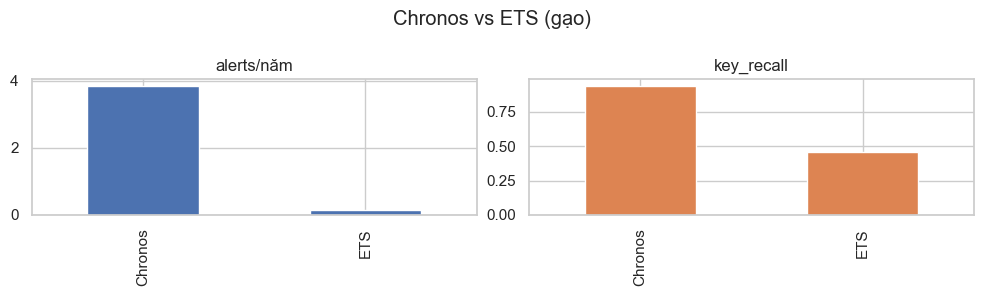

In [5]:
if payload is None:
    report_json = OUT / "chronos_vs_ets_gao.json"
    if report_json.exists():
        payload = json.loads(report_json.read_text(encoding="utf-8"))
    else:
        raise SystemExit("Chưa có kết quả Chronos (blocked hoặc chưa chạy cell trước).")

baseline = json.loads(BASELINE_JSON.read_text(encoding="utf-8"))["series"]["gạo"]
print("Model:", payload.get("model_id"), "quantiles:", payload.get("quantiles"))
display(pd.Series(payload["decision"]))

cmp = pd.DataFrame(
    {
        "Chronos": {
            "alerts/năm": payload["alerts_per_year"]["WARN_or_CRITICAL"],
            "key_recall": (
                payload["recall"]["so_luong"]["x2.0"]
                + payload["recall"]["so_luong"]["x0.5"]
                + payload["recall"]["tri_gia"]["x2.0"]
                + payload["recall"]["tri_gia"]["x0.5"]
            )
            / 4,
        },
        "ETS": {
            "alerts/năm": baseline["alerts_per_year"]["WARN_or_CRITICAL"],
            "key_recall": baseline["key_recall"],
        },
    }
).T
display(cmp.round(3))
cmp.plot(kind="bar", subplots=True, layout=(1, 2), figsize=(10, 3), legend=False)
plt.suptitle("Chronos vs ETS (gạo)")
plt.tight_layout()
plt.show()


## 6. Interval vs thực tế

Đổi `col` giữa `so_luong` | `tri_gia` | `don_gia`.


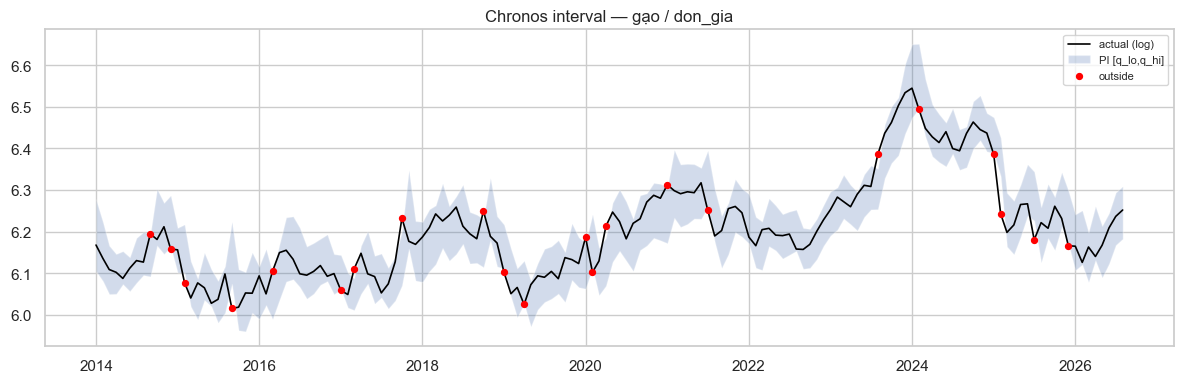

Outside rate: 0.145


In [6]:
col = "don_gia"  # so_luong | tri_gia | don_gia
path = OUT / f"chronos_gao_{col}.csv"
df_plot = pd.read_csv(path, parse_dates=["thang_nam"]).set_index("thang_nam")
lo = "q_lo" if "q_lo" in df_plot.columns else "q01"
hi = "q_hi" if "q_hi" in df_plot.columns else "q99"

fig, ax = plt.subplots()
ax.plot(df_plot.index, df_plot["y"], label="actual (log)", color="black", lw=1.2)
ax.fill_between(df_plot.index, df_plot[lo], df_plot[hi], alpha=0.25, label=f"PI [{lo},{hi}]")
out_pts = df_plot[df_plot["outside"]]
ax.scatter(out_pts.index, out_pts["y"], color="red", s=18, zorder=5, label="outside")
ax.set_title(f"Chronos interval — gạo / {col}")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print("Outside rate:", round(df_plot["outside"].mean(), 3))


## 7. Synthetic recall curves


,x1.2,x1.5,x2.0,x3.0,x0.7,x0.5,x0.3
so_luong,0.355,0.750,0.954,0.993,0.618,0.947,0.993
tri_gia,0.349,0.743,0.928,0.993,0.586,0.934,0.993


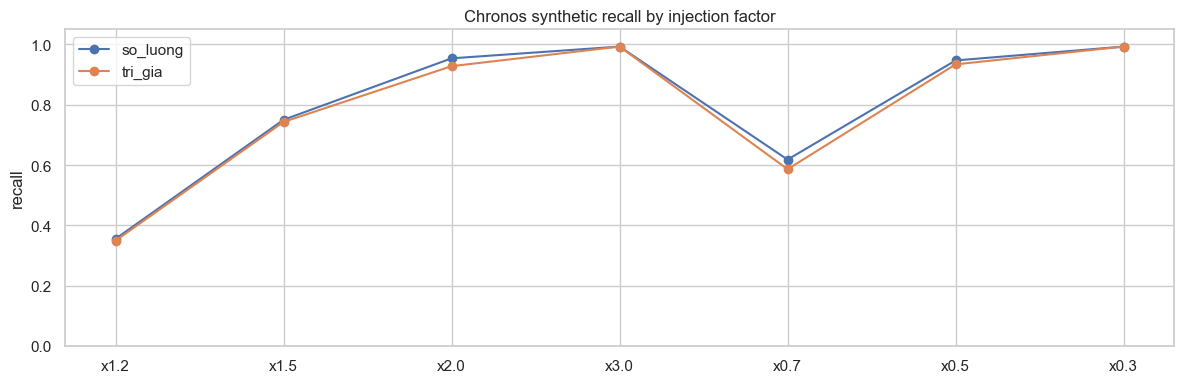

In [7]:
rec = pd.DataFrame(payload["recall"]).T
display(rec)
rec.T.plot(marker="o", title="Chronos synthetic recall by injection factor")
plt.ylabel("recall")
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()
